# Proyek Analisis Data: [Bike Sharing Dataset]
- **Nama:** [Baihaqi Alwi Mahmudi]
- **Email:** [baihaqialwi080@gmail.com]
- **ID Dicoding:** [haqi_mahmud]

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

- **Pertanyaan 1:** Bagaimana perbedaan jumlah penyewaan sepeda berdasarkan musim (season) selama periode 2011–2012, dan musim mana yang memiliki rata-rata penyewaan tertinggi untuk menentukan strategi penyediaan sepeda ?
- **Pertanyaan 2:** Bagaimana perbedaan jumlah penyewaan sepeda antara hari kerja dan hari libur selama periode 2011–2012, dan bagaimana pola tersebut dapat digunakan untuk menentukan kebutuhan operasional ?

## Import Semua Packages/Library yang Digunakan

In [163]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


In [164]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## Data Wrangling

### Gathering Data

#### Memuat Dataset Penyewaan Sepeda

In [165]:

# Load dataset
day_df = pd.read_csv("day.csv")
hour_df = pd.read_csv("hour.csv")

# Menampilkan 5 data pertama
day_df.head()


,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


In [166]:
hour_df.head()

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


### Assessing Data

#### Memeriksa Kualitas dan Kondisi Data

In [167]:

# Memeriksa informasi dataset harian
day_df.info()

# Memeriksa informasi dataset per jam
hour_df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   dteday      731 non-null    object 
 2   season      731 non-null    int64  
 3   yr          731 non-null    int64  
 4   mnth        731 non-null    int64  
 5   holiday     731 non-null    int64  
 6   weekday     731 non-null    int64  
 7   workingday  731 non-null    int64  
 8   weathersit  731 non-null    int64  
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null    float64
 13  casual      731 non-null    int64  
 14  registered  731 non-null    int64  
 15  cnt         731 non-null    int64  
dtypes: float64(4), int64(11), object(1)
memory usage: 91.5+ KB
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (tot

In [168]:

# Memeriksa missing value
print("Missing value pada day_df:")
print(day_df.isna().sum())

print("\nMissing value pada hour_df:")
print(hour_df.isna().sum())

# Memeriksa data duplikat
print("\nJumlah duplikat day_df:", day_df.duplicated().sum())
print("Jumlah duplikat hour_df:", hour_df.duplicated().sum())

# Melihat ringkasan statistik
display(day_df.describe())
display(hour_df.describe())


Missing value pada day_df:
instant       0
dteday        0
season        0
yr            0
mnth          0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64

Missing value pada hour_df:
instant       0
dteday        0
season        0
yr            0
mnth          0
hr            0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64

Jumlah duplikat day_df: 0
Jumlah duplikat hour_df: 0


,instant,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000
mean,366.000000,2.496580,0.500684,6.519836,0.028728,2.997264,0.683995,1.395349,0.495385,0.474354,0.627894,0.190486,848.176471,3656.172367,4504.348837
std,211.165812,1.110807,0.500342,3.451913,0.167155,2.004787,0.465233,0.544894,0.183051,0.162961,0.142429,0.077498,686.622488,1560.256377,1937.211452
min,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000,0.059130,0.079070,0.000000,0.022392,2.000000,20.000000,22.000000
25%,183.500000,2.000000,0.000000,4.000000,0.000000,1.000000,0.000000,1.000000,0.337083,0.337842,0.520000,0.134950,315.500000,2497.000000,3152.000000
50%,366.000000,3.000000,1.000000,7.000000,0.000000,3.000000,1.000000,1.000000,0.498333,0.486733,0.626667,0.180975,713.000000,3662.000000,4548.000000
75%,548.500000,3.000000,1.000000,10.000000,0.000000,5.000000,1.000000,2.000000,0.655417,0.608602,0.730209,0.233214,1096.000000,4776.500000,5956.000000
max,731.000000,4.000000,1.000000,12.000000,1.000000,6.000000,1.000000,3.000000,0.861667,0.840896,0.972500,0.507463,3410.000000,6946.000000,8714.000000


,instant,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,17379.0000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000
mean,8690.0000,2.501640,0.502561,6.537775,11.546752,0.028770,3.003683,0.682721,1.425283,0.496987,0.475775,0.627229,0.190098,35.676218,153.786869,189.463088
std,5017.0295,1.106918,0.500008,3.438776,6.914405,0.167165,2.005771,0.465431,0.639357,0.192556,0.171850,0.192930,0.122340,49.305030,151.357286,181.387599
min,1.0000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.020000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,4345.5000,2.000000,0.000000,4.000000,6.000000,0.000000,1.000000,0.000000,1.000000,0.340000,0.333300,0.480000,0.104500,4.000000,34.000000,40.000000
50%,8690.0000,3.000000,1.000000,7.000000,12.000000,0.000000,3.000000,1.000000,1.000000,0.500000,0.484800,0.630000,0.194000,17.000000,115.000000,142.000000
75%,13034.5000,3.000000,1.000000,10.000000,18.000000,0.000000,5.000000,1.000000,2.000000,0.660000,0.621200,0.780000,0.253700,48.000000,220.000000,281.000000
max,17379.0000,4.000000,1.000000,12.000000,23.000000,1.000000,6.000000,1.000000,4.000000,1.000000,1.000000,1.000000,0.850700,367.000000,886.000000,977.000000


**Steps to Take:**

- Mengubah tipe data kolom dteday menjadi datetime pada kedua dataset.

- Memastikan kembali tipe data setelah proses perubahan.

- Melanjutkan analisis menggunakan data yang sudah sesuai dengan kebutuhan.

### Cleaning Data

#### Membersihkan dan Menyesuaikan Data

In [169]:

# Mengubah tipe data tanggal
day_df["dteday"] = pd.to_datetime(day_df["dteday"])
hour_df["dteday"] = pd.to_datetime(hour_df["dteday"])

# Mengubah kode tahun menjadi tahun sebenarnya
year_names = {
    0: 2011,
    1: 2012
}
day_df["yr"] = day_df["yr"].map(year_names)
hour_df["yr"] = hour_df["yr"].map(year_names)

# Mengubah kode musim menjadi nama musim
season_names = {
    1: "Spring",
    2: "Summer",
    3: "Fall",
    4: "Winter"
}
day_df["season"] = day_df["season"].map(season_names)
hour_df["season"] = hour_df["season"].map(season_names)

# Mengubah kode jenis hari menjadi keterangan
workingday_names = {
    0: "Hari Libur",
    1: "Hari Kerja"
}
day_df["workingday"] = day_df["workingday"].map(workingday_names)
hour_df["workingday"] = hour_df["workingday"].map(workingday_names)

# Menghapus kolom yang tidak digunakan dalam analisis
day_df.drop(columns=["instant"], inplace=True)
hour_df.drop(columns=["instant"], inplace=True)

# Memeriksa hasil cleaning
print("Informasi day_df:")
day_df.info()

print("\nInformasi hour_df:")
hour_df.info()

print("\nJumlah missing value pada day_df:")
print(day_df.isna().sum().sum())

print("\nJumlah missing value pada hour_df:")
print(hour_df.isna().sum().sum())


Informasi day_df:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 15 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   dteday      731 non-null    datetime64[ns]
 1   season      731 non-null    object        
 2   yr          731 non-null    int64         
 3   mnth        731 non-null    int64         
 4   holiday     731 non-null    int64         
 5   weekday     731 non-null    int64         
 6   workingday  731 non-null    object        
 7   weathersit  731 non-null    int64         
 8   temp        731 non-null    float64       
 9   atemp       731 non-null    float64       
 10  hum         731 non-null    float64       
 11  windspeed   731 non-null    float64       
 12  casual      731 non-null    int64         
 13  registered  731 non-null    int64         
 14  cnt         731 non-null    int64         
dtypes: datetime64[ns](1), float64(4), int64(8), object(2)
me

In [170]:
print(day_df[["yr", "season", "workingday"]].head())
print(hour_df[["yr", "season", "workingday"]].head())

print("\nMissing value day_df:", day_df.isna().sum().sum())
print("Missing value hour_df:", hour_df.isna().sum().sum())

     yr  season  workingday
0  2011  Spring  Hari Libur
1  2011  Spring  Hari Libur
2  2011  Spring  Hari Kerja
3  2011  Spring  Hari Kerja
4  2011  Spring  Hari Kerja
     yr  season  workingday
0  2011  Spring  Hari Libur
1  2011  Spring  Hari Libur
2  2011  Spring  Hari Libur
3  2011  Spring  Hari Libur
4  2011  Spring  Hari Libur

Missing value day_df: 0
Missing value hour_df: 0


## Exploratory Data Analysis (EDA)

### Menganalisis Pola Penyewaan Sepeda

In [171]:
# Melihat statistik jumlah penyewaan sepeda
day_df["cnt"].describe()

,cnt
count,731.000000
mean,4504.348837
std,1937.211452
min,22.000000
25%,3152.000000
50%,4548.000000
75%,5956.000000
max,8714.000000


In [172]:
# Menghitung jumlah penyewaan berdasarkan musim
season_df = day_df.groupby("season").agg(
    jumlah_hari=("cnt", "count"),
    total_penyewaan=("cnt", "sum"),
    rata_rata=("cnt", "mean"),
    minimum=("cnt", "min"),
    maksimum=("cnt", "max")
).sort_values(by="rata_rata", ascending=False)

display(season_df)


,jumlah_hari,total_penyewaan,rata_rata,minimum,maksimum
season,,,,,
Fall,188,1061129,5644.303191,1115,8714
Summer,184,918589,4992.331522,795,8362
Winter,178,841613,4728.162921,22,8555
Spring,181,471348,2604.132597,431,7836


In [173]:
# Menghitung jumlah penyewaan berdasarkan jenis hari
workingday_df = day_df.groupby("workingday").agg(
    jumlah_hari=("cnt", "count"),
    total_penyewaan=("cnt", "sum"),
    rata_rata=("cnt", "mean"),
    minimum=("cnt", "min"),
    maksimum=("cnt", "max")
).sort_values(by="rata_rata", ascending=False)

display(workingday_df)

,jumlah_hari,total_penyewaan,rata_rata,minimum,maksimum
workingday,,,,,
Hari Kerja,500,2292410,4584.820000,22,8362
Hari Libur,231,1000269,4330.168831,605,8714


In [174]:
# Membandingkan rata-rata penyewaan setiap musim pada tahun 2011 dan 2012
year_season_df = day_df.groupby(["yr", "season"]).agg(
    total_penyewaan=("cnt", "sum"),
    rata_rata=("cnt", "mean")
).reset_index()

display(year_season_df)

,yr,season,total_penyewaan,rata_rata
0,2011,Fall,419650,4464.361702
1,2011,Spring,150000,1666.666667
2,2011,Summer,347316,3775.173913
3,2011,Winter,326137,3664.460674
4,2012,Fall,641479,6824.244681
5,2012,Spring,321348,3531.296703
6,2012,Summer,571273,6209.489130
7,2012,Winter,515476,5791.865169


## Visualization & Explanatory Analysis

### Pertanyaan 1: Bagaimana perbedaan jumlah penyewaan sepeda berdasarkan musim (season) selama periode 2011–2012, dan musim mana yang memiliki rata-rata penyewaan tertinggi untuk menentukan strategi penyediaan sepeda ?

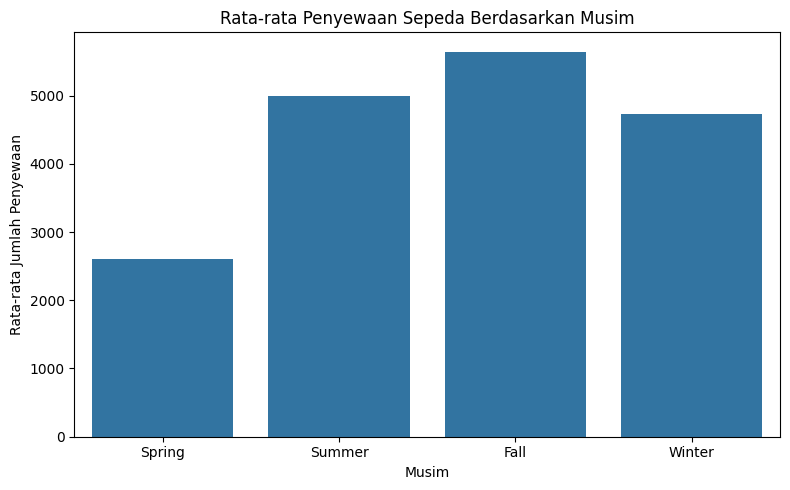

,season,cnt
0,Fall,5644.303191
2,Summer,4992.331522
3,Winter,4728.162921
1,Spring,2604.132597


In [175]:
# Menghitung rata-rata penyewaan sepeda berdasarkan musim
season_df = day_df.groupby("season")["cnt"].mean().reset_index()

# Membuat visualisasi
plt.figure(figsize=(8, 5))
sns.barplot(data=season_df, x="season", y="cnt", order=[
    "Spring", "Summer", "Fall", "Winter"
])

plt.title("Rata-rata Penyewaan Sepeda Berdasarkan Musim")
plt.xlabel("Musim")
plt.ylabel("Rata-rata Jumlah Penyewaan")
plt.tight_layout()
plt.show()

# Menampilkan musim dengan rata-rata penyewaan tertinggi
display(season_df.sort_values("cnt", ascending=False))

### Pertanyaan 2: Bagaimana perbedaan jumlah penyewaan sepeda antara hari kerja dan hari libur selama periode 2011–2012, dan bagaimana pola tersebut dapat digunakan untuk menentukan kebutuhan operasional

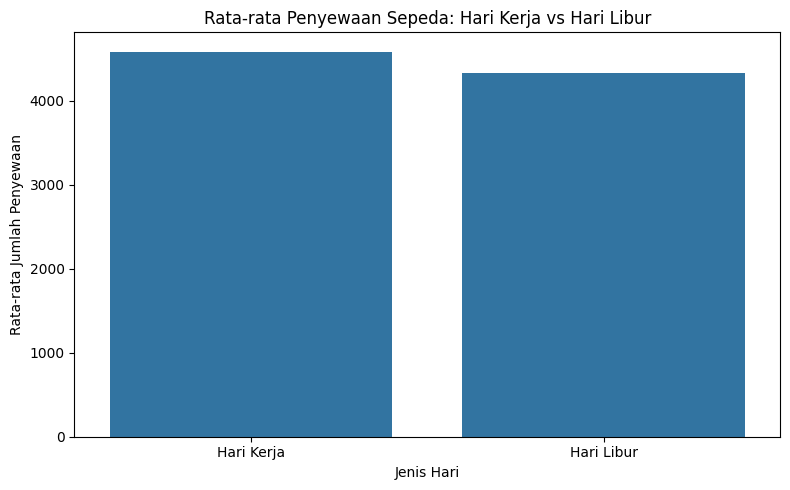

,workingday,cnt
0,Hari Kerja,4584.820000
1,Hari Libur,4330.168831


In [176]:
# Menghitung rata-rata penyewaan berdasarkan jenis hari
workingday_df = day_df.groupby("workingday")["cnt"].mean().reset_index()

# Membuat visualisasi
plt.figure(figsize=(8, 5))
sns.barplot(
    data=workingday_df,
    x="workingday",
    y="cnt",
    order=["Hari Kerja", "Hari Libur"]
)

plt.title("Rata-rata Penyewaan Sepeda: Hari Kerja vs Hari Libur")
plt.xlabel("Jenis Hari")
plt.ylabel("Rata-rata Jumlah Penyewaan")
plt.tight_layout()
plt.show()

# Menampilkan hasil rata-rata penyewaan
display(workingday_df.sort_values("cnt", ascending=False))

## Conclusion & Recommendation

- **Conclusion pertanyaan 1:** Penyewaan berdasarkan musim

Berdasarkan hasil analisis, musim Fall memiliki rata-rata penyewaan sepeda tertinggi, yaitu sekitar 5.644 sepeda per hari. Berikutnya adalah Summer sebesar 4.992 sepeda, Winter sebesar 4.728 sepeda, dan Spring sebesar 2.604 sepeda. Hal ini menunjukkan bahwa permintaan penyewaan sepeda tertinggi terjadi pada musim Fall, sedangkan yang terendah terjadi pada musim Spring. Oleh karena itu, penyedia layanan dapat menyesuaikan ketersediaan sepeda berdasarkan musim untuk memenuhi kebutuhan pelanggan.

- **Conclusion pertanyaan 2:** Penyewaan berdasarkan hari kerja dan hari libur

Berdasarkan hasil analisis, rata-rata penyewaan sepeda pada hari kerja mencapai sekitar 4.585 sepeda per hari, sedangkan pada hari libur sekitar 4.330 sepeda per hari. Dengan demikian, penyewaan sepeda pada hari kerja lebih tinggi daripada hari libur, dengan selisih sekitar 255 sepeda per hari. Hasil ini dapat menjadi pertimbangan dalam mengatur ketersediaan sepeda dan operasional layanan, terutama pada hari kerja.

**Rekomendasi Action Item:**

- Pengelolaan stok sepeda berdasarkan musim: Menambah kesiapan dan ketersediaan sepeda menjelang musim Fall karena memiliki rata-rata penyewaan tertinggi. Pada musim Spring, pengelola dapat memanfaatkan permintaan yang lebih rendah untuk melakukan perawatan sepeda.

- Penyesuaian operasional berdasarkan jenis hari: Menyiapkan ketersediaan sepeda dan petugas yang memadai pada hari kerja karena rata-rata penyewaannya lebih tinggi daripada hari libur.

- Evaluasi permintaan secara berkala: Memantau data penyewaan berdasarkan musim dan jenis hari agar pengelola dapat menyesuaikan persediaan sepeda serta jadwal perawatan sesuai pola permintaan.

In [177]:
# Menyimpan data harian yang sudah dibersihkan
day_df.to_csv("all_data.csv", index=False)